In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
import skdim
import scipy

from scipy.stats import gaussian_kde
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[202]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions =  counts_series.index.values)
    #
    # [item for item in counts_series.index.values if item not in ['root','void']])
# min_trials_per_condition=min_trials_per_condition,regions = ["Isocortex"])

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                     keepdims=True)) / np.std(z,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
print(response_matrix.shape)

Randomly selected eid: Data2/746d1902-fa59-4cab-b0aa-013be36060d5
cosmos
CB       144
HB      1138
HPF      195
HY       137
TH       796
root     111
dtype: int64
(200, 2510)


In [12]:
data_snr = []
for neuron in range(responses.shape[2]):
    means = []
    for t in range(99):
        h = (responses[:, t + 1, neuron] - responses[:, t, neuron]) / (responses[:, t, neuron] + 10)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))


In [134]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# --- 1. Model Components ---

class AffineCoupling(nn.Module):
    def __init__(self, dim, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim // 2, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, dim)
        )

    def forward(self, z, reverse=False):
        z1, z2 = z[:, :1], z[:, 1:]
        h = self.net(z1)
        shift, log_scale = h[:, :1], h[:, 1:]
        scale = torch.exp(torch.clamp(log_scale, -5, 2))

        if not reverse:
            z2_out = (z2 + shift) * scale
            ld = torch.log(scale).squeeze()
        else:
            z2_out = (z2 / scale) - shift
            ld = -torch.log(scale).squeeze()

        return torch.cat([z1, z2_out], dim=1), ld

class SequentialFlow(nn.Module):
    def __init__(self, n_layers=12):
        super().__init__()
        self.layers = nn.ModuleList([AffineCoupling(dim=2) for _ in range(n_layers)])

    def forward(self, z, reverse=False):
        total_ld = 0
        indices = range(len(self.layers)) if not reverse else reversed(range(len(self.layers)))
        for i in indices:
            z, ld = self.layers[i](z, reverse=reverse)
            total_ld += ld
            z = torch.cat([z[:, 1:], z[:, :1]], dim=1)
        return z, total_ld

class IsometricAE(nn.Module):
    def __init__(self, input_dim=200, latent_dim=2):
        super().__init__()
        # Increased depth/width for 200D -> 2D compression
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

# --- 2. Data Preparation ---

# Assuming response_matrix is already defined in your environment
# X_tensor = torch.FloatTensor(response_matrix.T)

# For demonstration, creating a dummy response_matrix (200 features, 1000 samples)
X_tensor = torch.FloatTensor(response_matrix.T)
X_scaled = X_tensor/torch.linalg.norm(X_tensor, dim=1, keepdim=True)

# --- 3. Stage 1: Train 200D Isometric AE ---

input_dim = 200
ae = IsometricAE(input_dim=input_dim, latent_dim=2)
ae_opt = optim.Adam(ae.parameters(), lr=1e-3)

print(f"Step 1: Training Isometric AE (Input Dim: {input_dim})...")
for i in range(15000):
    ae_opt.zero_grad()
    z = ae.encoder(X_scaled)
    x_hat = ae.decoder(z)

    recon = torch.mean((x_hat - X_scaled)**2)

    # Isometry: ensure the 2D latent distances reflect 200D manifold distances
    v = torch.randn_like(z)
    _, v_jvp = torch.autograd.functional.jvp(ae.decoder, z, v, create_graph=True)
    iso = torch.mean((torch.norm(v_jvp, dim=1)**2 - torch.norm(v, dim=1)**2)**2)

    loss = recon + 0.5 * iso
    loss.backward()
    ae_opt.step()
    if i % 500 == 0:
        print(f"Iter {i:4d} | Recon: {recon.item():.6f} | Iso: {iso.item():.6f}")



Step 1: Training Isometric AE (Input Dim: 200)...
Iter    0 | Recon: 0.018328 | Iso: 1.206658
Iter  500 | Recon: 0.004732 | Iso: 0.001509
Iter 1000 | Recon: 0.003592 | Iso: 0.002972
Iter 1500 | Recon: 0.002795 | Iso: 0.000322
Iter 2000 | Recon: 0.002558 | Iso: 0.000871
Iter 2500 | Recon: 0.002216 | Iso: 0.000345
Iter 3000 | Recon: 0.002095 | Iso: 0.000178
Iter 3500 | Recon: 0.002074 | Iso: 0.000173
Iter 4000 | Recon: 0.002066 | Iso: 0.000429
Iter 4500 | Recon: 0.002062 | Iso: 0.000154
Iter 5000 | Recon: 0.002058 | Iso: 0.000159
Iter 5500 | Recon: 0.002058 | Iso: 0.000017
Iter 6000 | Recon: 0.002054 | Iso: 0.000016
Iter 6500 | Recon: 0.002053 | Iso: 0.000031
Iter 7000 | Recon: 0.002050 | Iso: 0.000071
Iter 7500 | Recon: 0.002045 | Iso: 0.000068
Iter 8000 | Recon: 0.002039 | Iso: 0.000045
Iter 8500 | Recon: 0.002026 | Iso: 0.000049
Iter 9000 | Recon: 0.002015 | Iso: 0.000164
Iter 9500 | Recon: 0.001988 | Iso: 0.000112
Iter 10000 | Recon: 0.001961 | Iso: 0.000517
Iter 10500 | Recon: 0.001

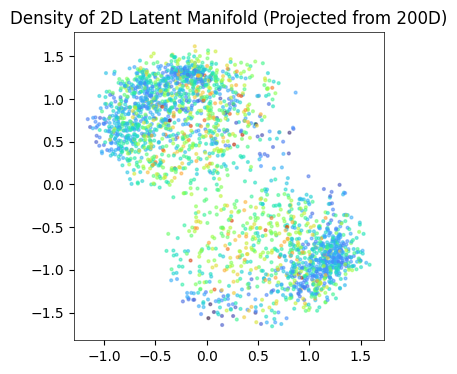

In [136]:
plt.figure(figsize=(4,4))
Z_fixed = ae.encoder(X_scaled).detach()
#plt.tricontourf(x_p, y_p, z_p, levels=50, cmap='magma')
plt.scatter(Z_fixed[:,0], Z_fixed[:,1], c=data_snr,cmap = 'turbo', s=4, alpha=0.5)
plt.title(f"Density of 2D Latent Manifold (Projected from {input_dim}D)")
plt.show()

AttributeError: 'RealNVP' object has no attribute 'sample'

AttributeError: 'RealNVP' object has no attribute 'sample'

Epoch 0, Loss: 3.0514
Epoch 200, Loss: 1.4198
Epoch 400, Loss: 1.4081
Epoch 600, Loss: 1.4026
Epoch 800, Loss: 1.4012
Epoch 1000, Loss: 1.3991
Epoch 1200, Loss: 1.3932
Epoch 1400, Loss: 1.3934
Epoch 1600, Loss: 1.3879
Epoch 1800, Loss: 1.3863
Epoch 2000, Loss: 1.3898
Epoch 2200, Loss: 1.3873
Epoch 2400, Loss: 1.3787
Epoch 2600, Loss: 1.3760
Epoch 2800, Loss: 1.3760
Epoch 3000, Loss: 1.3743
Epoch 3200, Loss: 1.3703
Epoch 3400, Loss: 1.3735
Epoch 3600, Loss: 1.3707
Epoch 3800, Loss: 1.3664
Epoch 4000, Loss: 1.3700
Epoch 4200, Loss: 1.3705
Epoch 4400, Loss: 1.3666
Epoch 4600, Loss: 1.3660
Epoch 4800, Loss: 1.3596


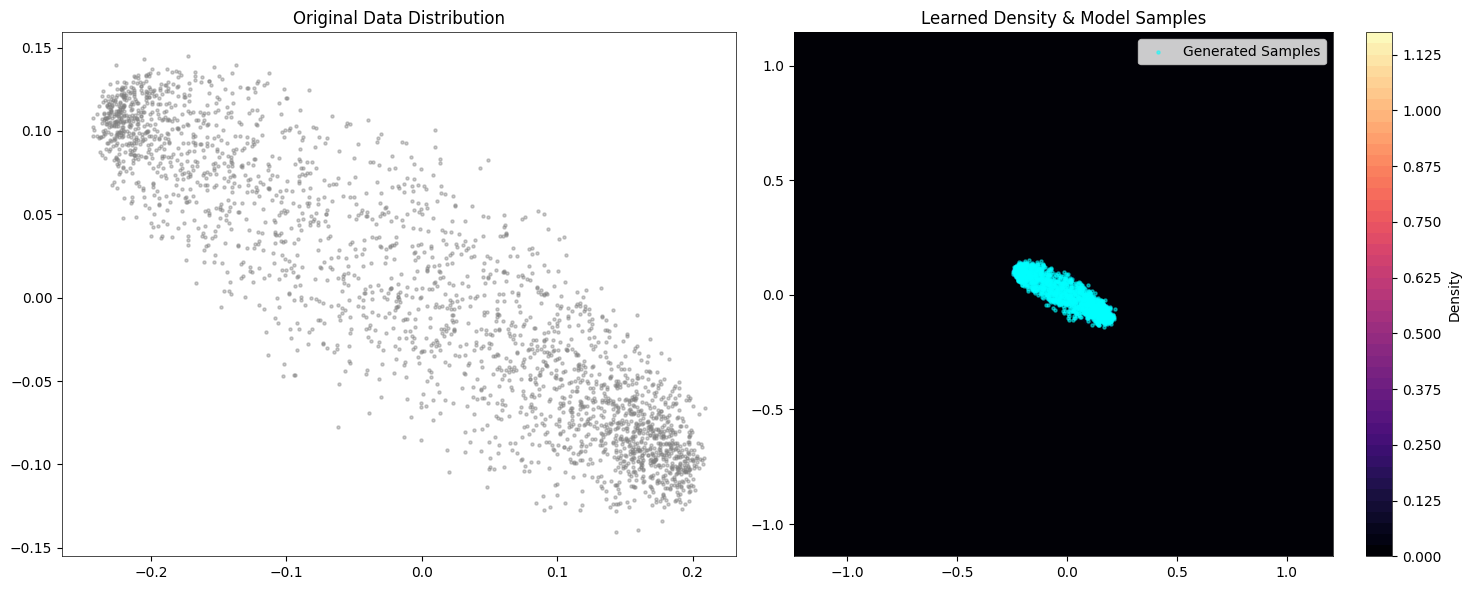

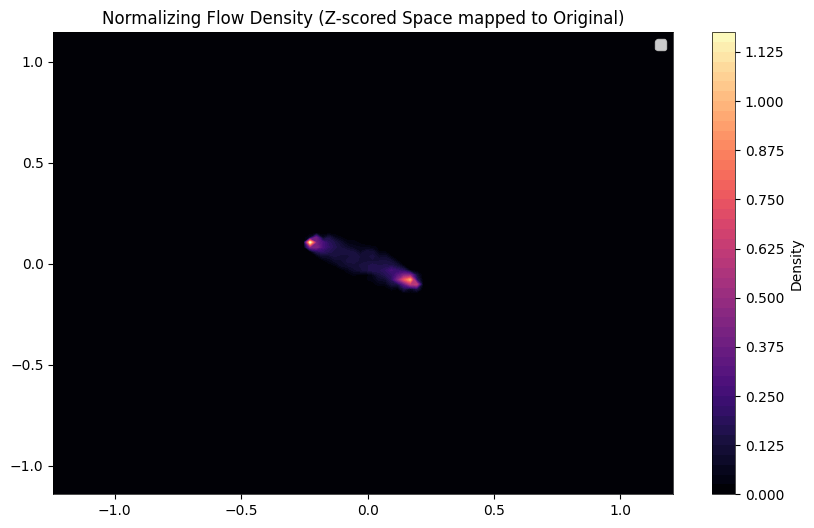

In [120]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# --- 1. Data Normalization Utility ---
class Standardizer:
    def __init__(self, data):
        self.mean = data.mean(dim=0)
        self.std = data.std(dim=0)

    def transform(self, data):
        return (data - self.mean) / (self.std + 1e-6)

    def inverse_transform(self, data):
        return (data * (self.std + 1e-6)) + self.mean

# --- 2. Model Components (RealNVP) ---
class CouplingLayer(nn.Module):
    def __init__(self, input_dim, hidden_dim, mask):
        super().__init__()
        self.mask = nn.Parameter(mask, requires_grad=False)
        self.nn = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim * 2)
        )

    def forward(self, x, reverse=False):
        x_masked = x * self.mask
        out = self.nn(x_masked)
        s, t = out.chunk(2, dim=1)
        s = torch.tanh(s)

        if not reverse:
            z = x_masked + (1 - self.mask) * (x - t) * torch.exp(-s)
            log_det_jac = torch.sum((1 - self.mask) * (-s), dim=1)
            return z, log_det_jac
        else:
            x = x_masked + (1 - self.mask) * (x * torch.exp(s) + t)
            return x

class RealNVP(nn.Module):
    def __init__(self, num_layers=6, hidden_dim=64):
        super().__init__()
        self.layers = nn.ModuleList()
        masks = [torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])] * (num_layers // 2)
        for mask in masks:
            self.layers.append(CouplingLayer(2, hidden_dim, mask))

    def log_prob(self, x):
        log_det_sum = 0
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_sum += log_det
        log_p_z = -0.5 * (torch.log(torch.tensor(2 * np.pi)) + z**2).sum(dim=1)
        return log_p_z + log_det_sum

    # --- ADD THIS METHOD ---
    def sample(self, num_samples):
        # 1. Sample from the base distribution (Standard Normal)
        z = torch.randn(num_samples, 2)
        # 2. Run through layers in REVERSE order
        for layer in reversed(self.layers):
            z = layer(z, reverse=True)
        return z

# --- 3. Training Loop ---
# Generate data with an offset/scale to test the Z-scoring
raw_X = Z_fixed
# Apply Z-scoring
standardizer = Standardizer(raw_X)
X_scaled = standardizer.transform(raw_X)

model = RealNVP()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5000):
    optimizer.zero_grad()
    loss = -model.log_prob(X_scaled).mean()
    loss.backward()
    optimizer.step()
    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# --- 4. Plotting on Original Scale ---


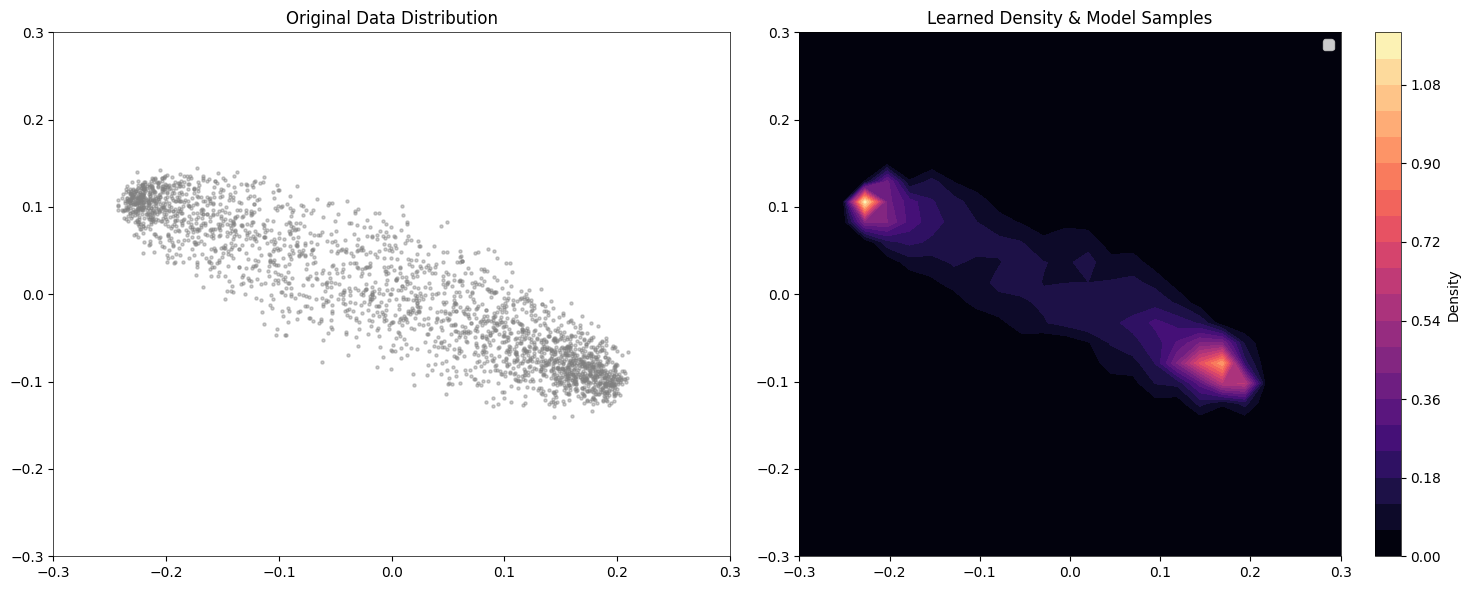

In [125]:
def plot_comparison(model, standardizer, raw_data, num_samples=20000):
    model.eval()

    # 1. Generate Samples from the model
    with torch.no_grad():
        # Sample from N(0,1) -> Transform through Flow -> Inverse Z-score
        z_samples = model.sample(num_samples)
        x_samples_scaled = z_samples
        x_samples_raw = standardizer.inverse_transform(x_samples_scaled).numpy()

    # 2. Create Density Grid for Contours
    x_min, x_max = raw_data[:, 0].min() - 1, raw_data[:, 0].max() + 1
    y_min, y_max = raw_data[:, 1].min() - 1, raw_data[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
    grid_raw = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    with torch.no_grad():
        grid_scaled = standardizer.transform(grid_raw)
        probs = model.log_prob(grid_scaled).exp().reshape(xx.shape).numpy()

    # 3. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Left Plot: Original Data
    axes[0].scatter(raw_data[:, 0], raw_data[:, 1], s=5, color='gray', alpha=0.4)
    axes[0].set_title("Original Data Distribution")
    axes[0].set_xlim(-.3,.3)
    axes[0].set_ylim(-.3,.3)

    # Right Plot: Model Density + Generated Samples
    # Use a contourf to show the "landscape" the model learned
    cont = axes[1].contourf(xx, yy, probs, levels=20, cmap='magma')
    # Overlay actual samples generated by the model
    # axes[1].scatter(x_samples_raw[:, 0], x_samples_raw[:, 1], s=5,
    #                 color='cyan', alpha=0.5, label='Generated Samples')

    axes[1].set_title("Learned Density & Model Samples")
    axes[1].set_xlim(-.3,.3)
    axes[1].set_ylim(-.3,.3)
    axes[1].legend()

    plt.colorbar(cont, ax=axes[1], label='Density')
    plt.tight_layout()
    plt.show()

# Run the comparison
plot_comparison(model, standardizer, raw_X)

